# 5. Behavioral risk classification — not verified bot identity

100 manual reviews, seed 2026, **stratified on the rule engine’s own bands** (35 low / 30 medium / 35 high) — **not** a simple random sample.

The high-risk band has only 99 users in the whole population, so drawing 35 of them enriches that band by ~136×. Precision / recall on these 98 usable labels are **sample diagnostics, not population estimates**.

ML uses **98** usable labels (2 `insufficient_evidence` excluded). K=5 mean train size **78**; LOOCV train size **97**.

The required **200-user validation set is missing and was not fabricated**.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


manual reviews 100
manual_label
likely_normal            39
suspicious               30
likely_malicious         29
insufficient_evidence     2
is_bot value counts
is_bot
unknown    61
0          39
usable ML labels 98
K=5 mean n_train 78.0
LOOCV n_train 97.0
[embedded figure] malicious_detection_flow.png (427,627 bytes)
[embedded figure] bot_model_comparison.png (51,140 bytes)
DONE bot verification


,algorithm,training_type,n_train,precision,recall,F1
0,Logistic Regression,kfold_k5_fold1,78,1.0000,0.8333,0.9091
1,Logistic Regression,kfold_k5_fold2,78,0.6429,0.7500,0.6923
2,Logistic Regression,kfold_k5_fold3,78,0.9231,1.0000,0.9600
3,Logistic Regression,kfold_k5_fold4,79,0.7857,0.9167,0.8462
4,Logistic Regression,kfold_k5_fold5,79,0.6667,0.7273,0.6957
5,Logistic Regression,kfold_k5_pooled,78,0.7937,0.8475,0.8197
6,Logistic Regression,kfold_k5_mean,78,0.8037,0.8455,0.8207
7,Decision Tree,kfold_k5_fold1,78,0.9091,0.8333,0.8696
8,Decision Tree,kfold_k5_fold2,78,0.6923,0.7500,0.7200
9,Decision Tree,kfold_k5_fold3,78,0.7273,0.6667,0.6957


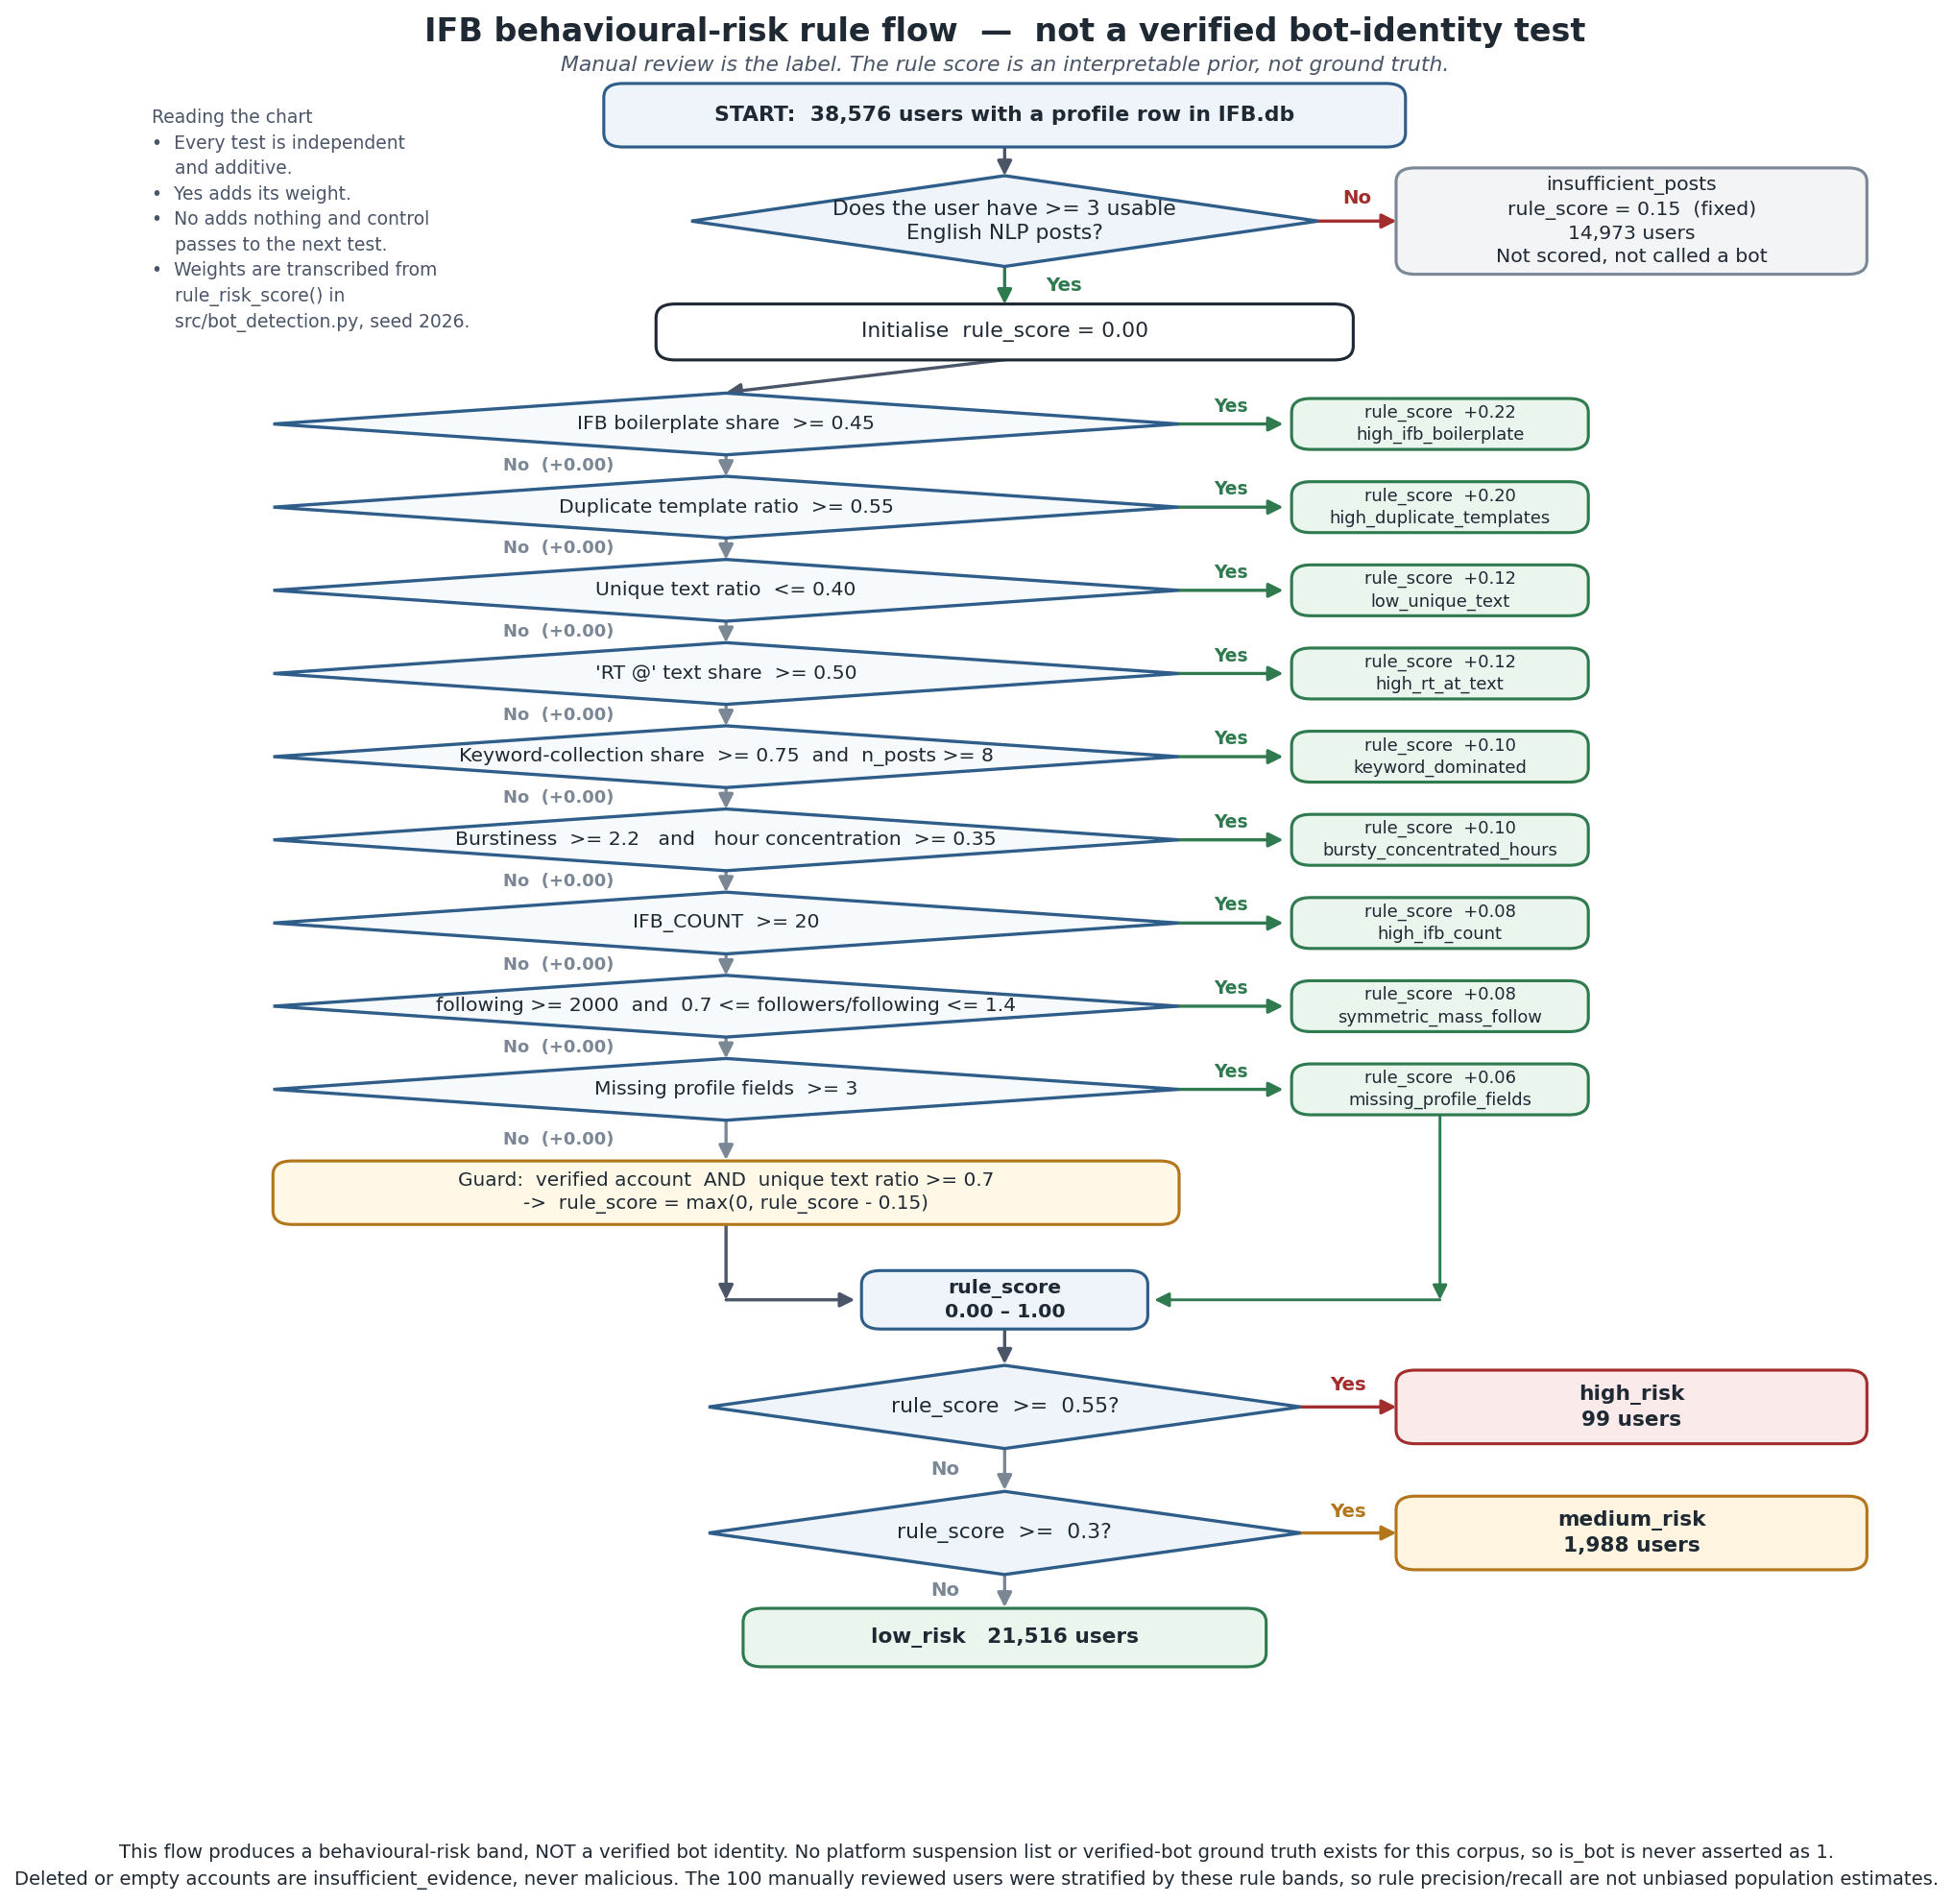

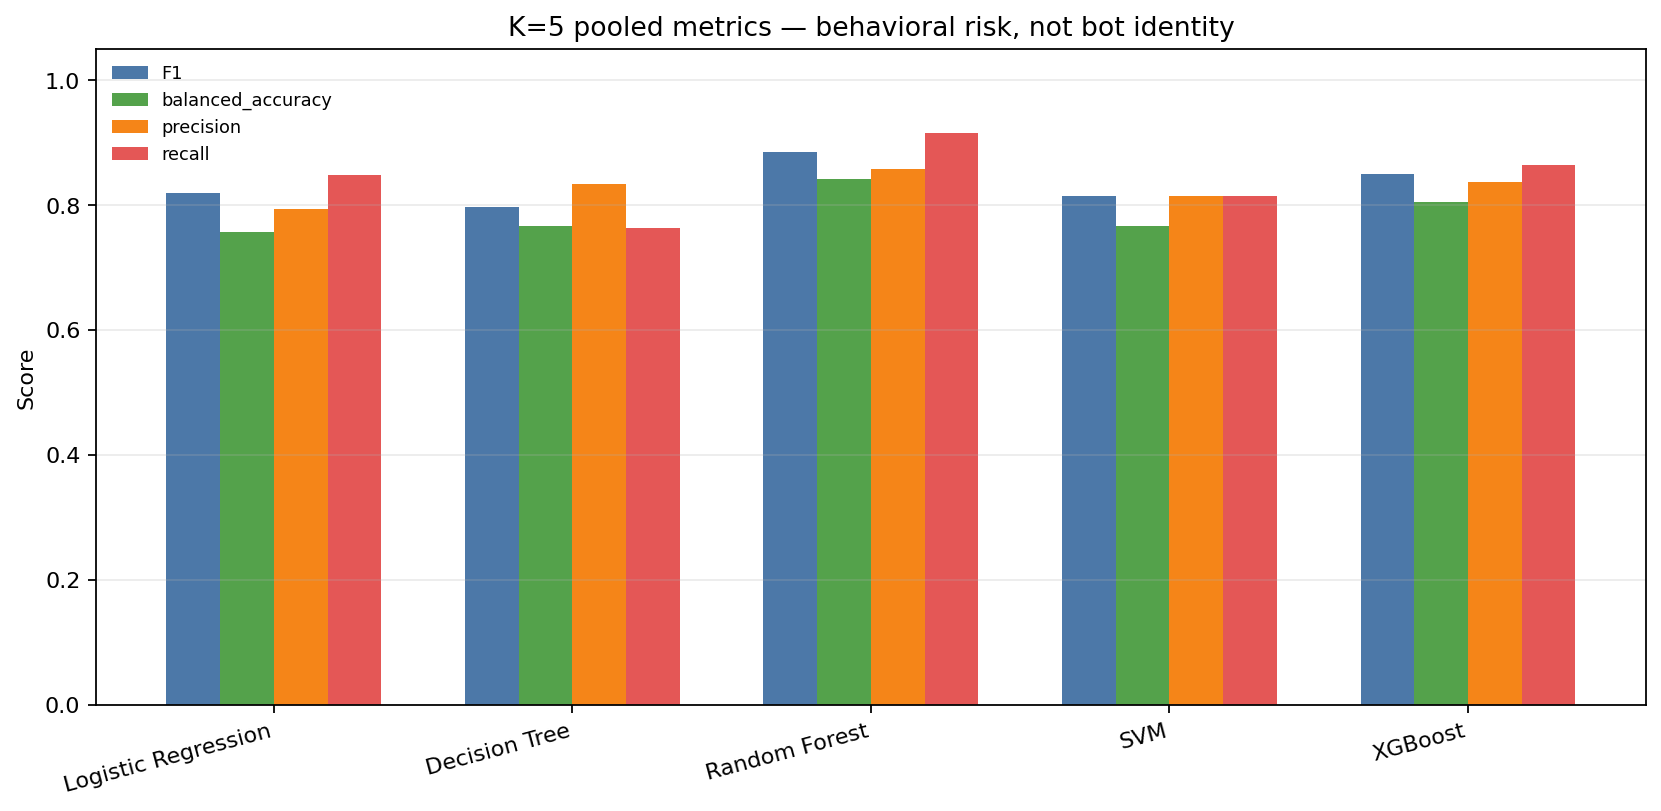

In [2]:
lab = pd.read_csv(OUT / "labeled_bots_and_not_bots.csv", encoding="utf-8-sig")
exp = pd.read_csv(OUT / "bot_detection_experiments.csv", encoding="utf-8-sig")
print("manual reviews", len(lab))
assert len(lab) == 100
print(lab["manual_label"].value_counts(dropna=False).to_string())
print("is_bot value counts")
print(lab["is_bot"].value_counts(dropna=False).to_string())
usable = lab[lab["manual_label"] != "insufficient_evidence"]
print("usable ML labels", len(usable))
assert len(usable) == 98
k5 = exp[exp["training_type"].astype(str).str.contains("kfold_k5_mean", na=False)]
loo = exp[exp["training_type"].astype(str).str.contains("loocv", na=False)]
if len(k5):
    print("K=5 mean n_train", k5["n_train"].astype(float).mean())
if len(loo):
    print("LOOCV n_train", loo["n_train"].astype(float).iloc[0])
display(exp[["algorithm", "training_type", "n_train", "precision", "recall", "F1"]].head(16)
        if set(["algorithm", "training_type"]).issubset(exp.columns) else exp.head(16))
display(Image(filename=str(OUT / "malicious_detection_flow.png")))
display(Image(filename=str(OUT / "bot_model_comparison.png")))
print("DONE bot verification")
